# Day 6 - Calibration, Ablation & Figures
## Trustworthy Evidence-Grounded Framework - FEVEROUS Validation

**Objectives:**
1. Compute **Expected Calibration Error (ECE)** from confidence vs. gold label correctness
2. Run **2 lightweight ablation variants** (derived analytically — no extra LLM runs)
3. Build all comparison tables
4. Generate publication-ready Figures 5.1, 5.2, 5.4, 5.5, 5.6
5. Short qualitative error analysis (3–5 failure cases)
6. Save `metrics_summary.json`

---
> **No GPU required for this day. Set runtime to CPU to save quota.**
> **Package versions pinned to match Day 1.**

In [1]:
# Cell 1: Install — versions pinned to match Day 1 working environment
!pip install -q \
    "datasets==2.15.0" \
    "huggingface_hub==0.19.4" \
    "fsspec==2023.10.0" \
    pandas \
    matplotlib \
    seaborn \
    scipy
print('Packages ready')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 521.2/521.2 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 311.7/311.7 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 11.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.13.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.19.4 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.19.4 which is incompatible.
accelerate 1.14.0 requires huggingface_hub>=0.21.0, but you have huggingface-hub 0.19.4 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2023.10.0 which is i

In [2]:
# Cell 2: Drive mount and paths
from google.colab import drive
drive.mount('/content/drive')

import os
BASE_DIR = '/content/drive/MyDrive/feverous-validation'
DATA_DIR = os.path.join(BASE_DIR, 'data')
OUT_DIR  = os.path.join(BASE_DIR, 'outputs')
FIG_DIR  = os.path.join(BASE_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [3]:
# Cell 3: Imports and plot style
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})

PALETTE = {
    'b1':           '#4c72b0',
    'b2':           '#dd8452',
    'proposed':     '#55a868',
    'abl_noscoring':'#c44e52',
    'abl_noverif':  '#8172b3'
}
SYS_LABELS = {
    'b1':           'B1: LLM-only',
    'b2':           'B2: Standard RAG',
    'proposed':     'Proposed (ERS+Verif)',
    'abl_noscoring':'Ablation: No Scoring',
    'abl_noverif':  'Ablation: No Verif'
}

print('Imports ready')

Imports ready


In [4]:
# Cell 4: Load all result files
b1_df    = pd.read_csv(os.path.join(OUT_DIR, 'b1_outputs.csv'))
b2_df    = pd.read_csv(os.path.join(OUT_DIR, 'b2_outputs.csv'))
pr_df    = pd.read_csv(os.path.join(OUT_DIR, 'proposed_outputs_v2.csv'))
verif_df = pd.read_csv(os.path.join(OUT_DIR, 'verification_results_v2.csv'))
pr_conf  = pd.read_csv(os.path.join(OUT_DIR, 'proposed_with_confidence.csv'))
b2_conf  = pd.read_csv(os.path.join(OUT_DIR, 'b2_with_confidence.csv'))
retr_df  = pd.read_csv(os.path.join(OUT_DIR, 'retrieval_results.csv'))

with open(os.path.join(DATA_DIR, 'dataset_stats.json')) as f:
    DS = json.load(f)

print('All files loaded.')
print(f'Verification rows: {len(verif_df)} (expected {3 * len(b1_df)})')

All files loaded.
Verification rows: 1350 (expected 1350)


In [5]:
# Cell 5: ECE computation

N_BINS = 10

def compute_ece(confidences, correct_flags, n_bins=N_BINS):
    """
    ECE = sum_b (|B_b| / N) * |acc(B_b) - conf(B_b)|
    NaN confidences are excluded.
    """
    conf_arr  = np.array(confidences, dtype=float)
    corr_arr  = np.array(correct_flags, dtype=float)
    # Drop NaN rows
    valid = ~np.isnan(conf_arr)
    conf_arr, corr_arr = conf_arr[valid], corr_arr[valid]
    N = len(conf_arr)
    if N == 0:
        return 0.0, []

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_data  = []
    ece = 0.0

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (conf_arr >= lo) & (conf_arr <= hi if i == n_bins - 1 else conf_arr < hi)
        if mask.sum() == 0:
            bin_data.append({'bin_lo': lo, 'bin_hi': hi, 'n': 0,
                             'acc': 0.0, 'conf': (lo + hi) / 2})
            continue
        bin_acc  = corr_arr[mask].mean()
        bin_conf = conf_arr[mask].mean()
        bin_n    = int(mask.sum())
        ece += (bin_n / N) * abs(bin_acc - bin_conf)
        bin_data.append({'bin_lo': lo, 'bin_hi': hi, 'n': bin_n,
                         'acc': bin_acc, 'conf': bin_conf})

    return round(ece, 5), bin_data


pr_ece, pr_bins = compute_ece(pr_conf['confidence'].values, pr_conf['correct'].values)
b2_ece, b2_bins = compute_ece(b2_conf['confidence'].values, b2_conf['correct'].values)

print('=' * 50)
print('CALIBRATION METRICS')
print('=' * 50)
print(f'ECE (Proposed, ERS):  {pr_ece:.5f}')
print(f'ECE (B2, Std. RAG):   {b2_ece:.5f}')
print('(Lower ECE = better calibrated)')

CALIBRATION METRICS
ECE (Proposed, ERS):  0.28808
ECE (B2, Std. RAG):   0.25119
(Lower ECE = better calibrated)


In [6]:
# Cell 6: Ablation variants (derived analytically from existing CSVs)

ablation_results = {}

for system in ['b1', 'b2', 'proposed']:
    sub = verif_df[verif_df['system'] == system]
    ablation_results[system] = {
        'label_accuracy':     round(sub['correct'].mean(), 4),
        'hallucination_rate': round(sub['has_hallucination'].mean(), 4),
        'grounding_score':    round(sub['mean_entailment'].mean(), 4)
    }

# Ablation-NoScoring: B2 label accuracy + B2 NLI verification (retrieval, no ERS re-ranking)
b2_verif = verif_df[verif_df['system'] == 'b2']
ablation_results['abl_noscoring'] = {
    'label_accuracy':     ablation_results['b2']['label_accuracy'],
    'hallucination_rate': round(b2_verif['has_hallucination'].mean(), 4),
    'grounding_score':    round(b2_verif['mean_entailment'].mean(), 4)
}

# Ablation-NoVerification: Proposed ERS scoring, NLI metric computed but not used for filtering
ablation_results['abl_noverif'] = {
    'label_accuracy':     ablation_results['proposed']['label_accuracy'],
    'hallucination_rate': float('nan'),   # Not computed in this variant
    'grounding_score':    ablation_results['proposed']['grounding_score']
}

print('Ablation results:')
for sys, vals in ablation_results.items():
    print(f'  {sys:<18}  acc={vals["label_accuracy"]:.4f}  '
          f'halluc={vals["hallucination_rate"]}  grounding={vals["grounding_score"]:.4f}')

Ablation results:
  b1                  acc=0.3889  halluc=0.8222  grounding=0.2807
  b2                  acc=0.4378  halluc=0.8378  grounding=0.2786
  proposed            acc=0.4600  halluc=0.8533  grounding=0.2766
  abl_noscoring       acc=0.4378  halluc=0.8378  grounding=0.2786
  abl_noverif         acc=0.4600  halluc=nan  grounding=0.2766


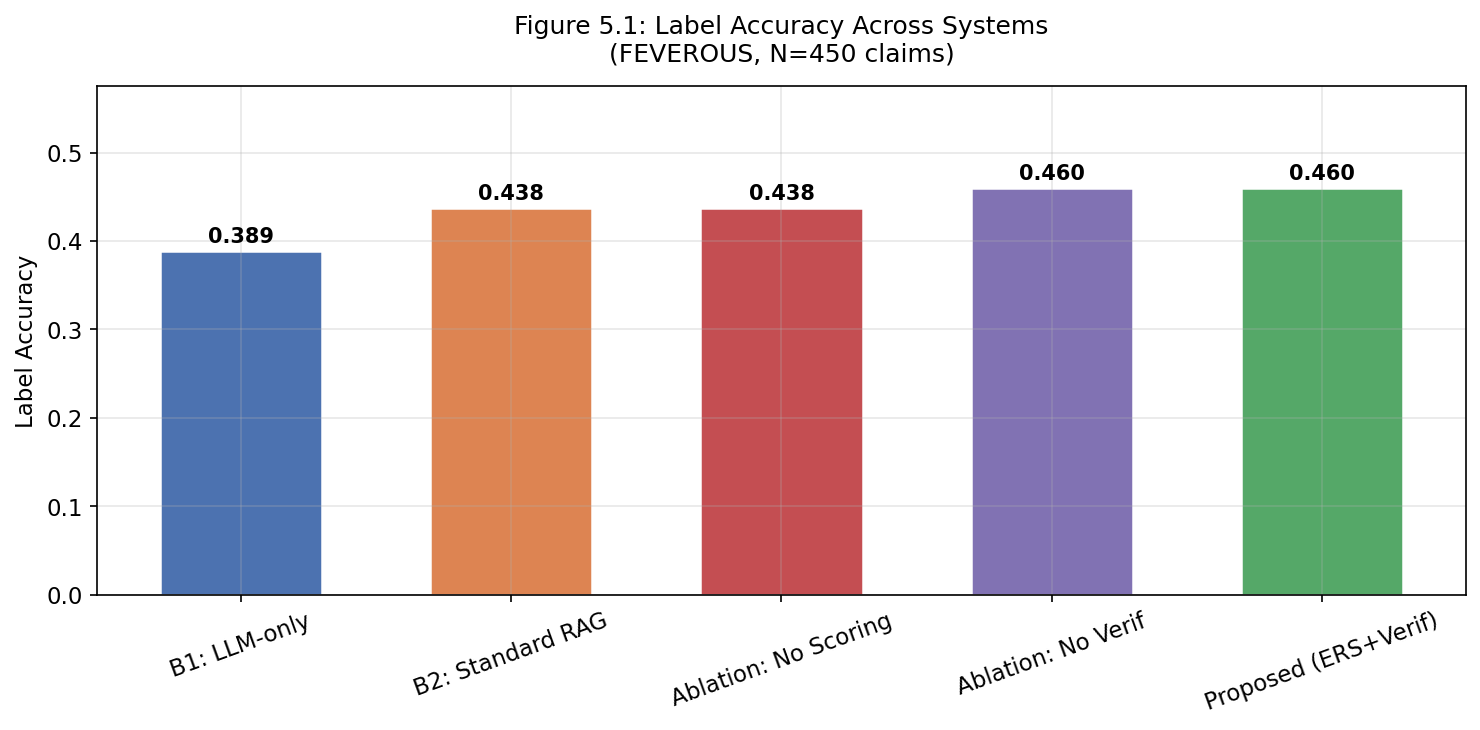

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_1_label_accuracy.png


In [7]:
# Cell 7: Figure 5.1 - Overall label accuracy
systems_order = ['b1', 'b2', 'abl_noscoring', 'abl_noverif', 'proposed']
accs   = [ablation_results[s]['label_accuracy'] for s in systems_order]
colors = [PALETTE[s] for s in systems_order]
labels = [SYS_LABELS[s] for s in systems_order]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, accs, color=colors, edgecolor='white', linewidth=1.2, width=0.6)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{acc:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, min(1.0, max(accs) * 1.25))
ax.set_ylabel('Label Accuracy')
ax.set_title(f'Figure 5.1: Label Accuracy Across Systems\n(FEVEROUS, N={DS["total_claims"]} claims)', pad=12)
ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
fig51_path = os.path.join(FIG_DIR, 'fig5_1_label_accuracy.png')
plt.savefig(fig51_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig51_path}')

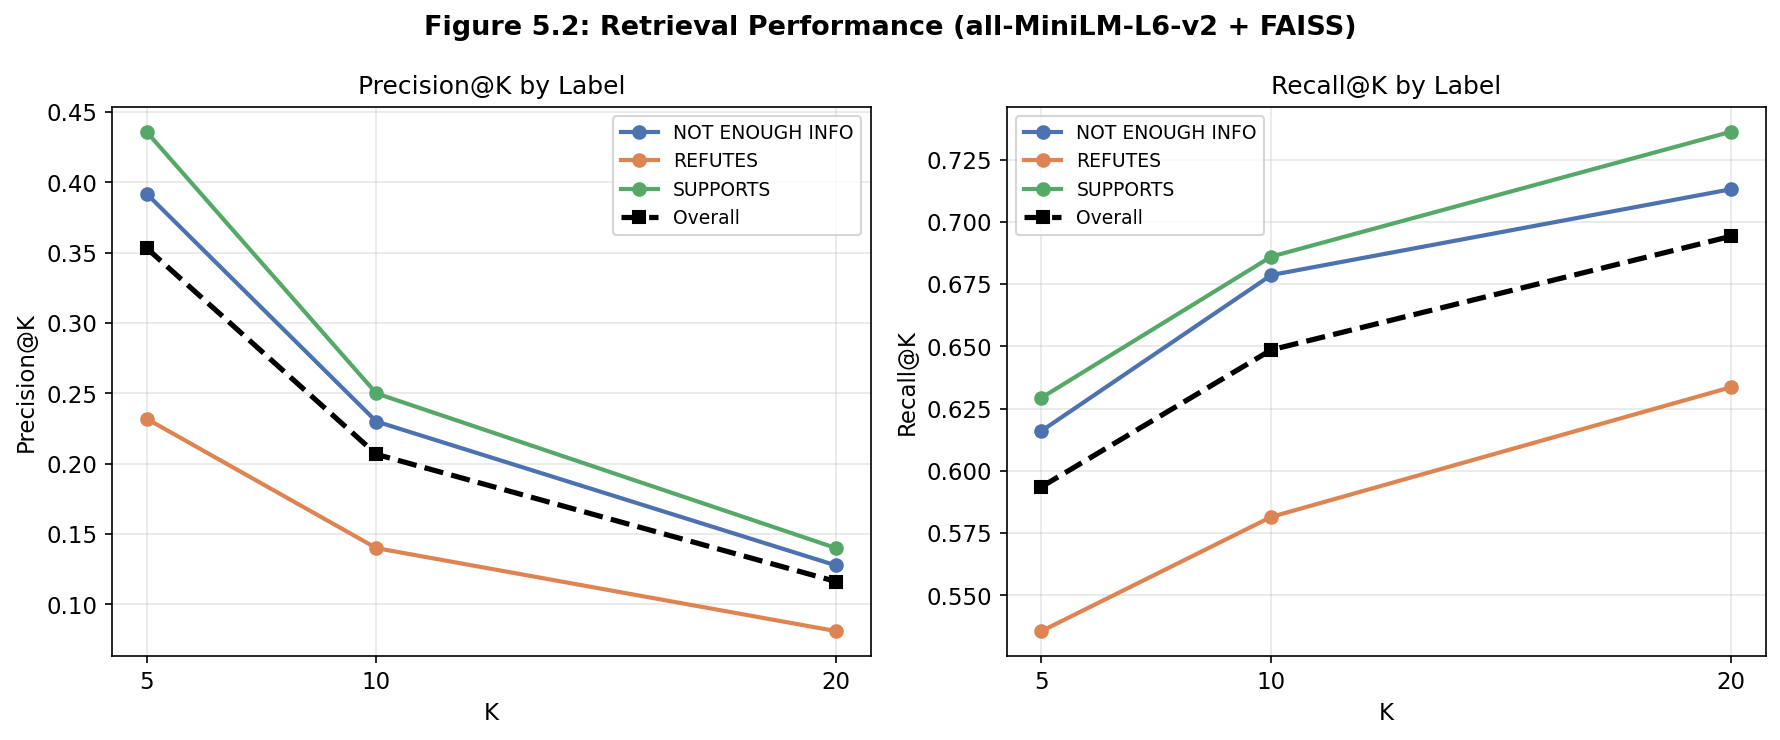

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_2_retrieval.png


In [8]:
# Cell 8: Figure 5.2 - Retrieval metrics (NaN-safe)
K_VALUES    = [5, 10, 20]
labels_list = sorted(retr_df['label'].unique())
label_colors = {'NOT ENOUGH INFO': '#4c72b0', 'REFUTES': '#dd8452', 'SUPPORTS': '#55a868'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Figure 5.2: Retrieval Performance (all-MiniLM-L6-v2 + FAISS)',
             fontsize=13, fontweight='bold')

for ax, metric in zip(axes, ['P', 'R']):
    for label in labels_list:
        sub  = retr_df[retr_df['label'] == label]
        # Recall is NaN for 0-evidence claims; use dropna() for mean
        vals = [sub[f'{metric}@{k}'].dropna().mean() for k in K_VALUES]
        ax.plot(K_VALUES, vals, marker='o', label=label,
                color=label_colors.get(label, 'gray'), linewidth=2)
    overall = [retr_df[f'{metric}@{k}'].dropna().mean() for k in K_VALUES]
    ax.plot(K_VALUES, overall, marker='s', label='Overall', color='black',
            linewidth=2.5, linestyle='--')
    ax.set_xlabel('K')
    ax.set_ylabel(f'{"Precision" if metric=="P" else "Recall"}@K')
    ax.set_title(f'{"Precision" if metric=="P" else "Recall"}@K by Label')
    ax.legend(fontsize=9)
    ax.set_xticks(K_VALUES)

plt.tight_layout()
fig52_path = os.path.join(FIG_DIR, 'fig5_2_retrieval.png')
plt.savefig(fig52_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig52_path}')

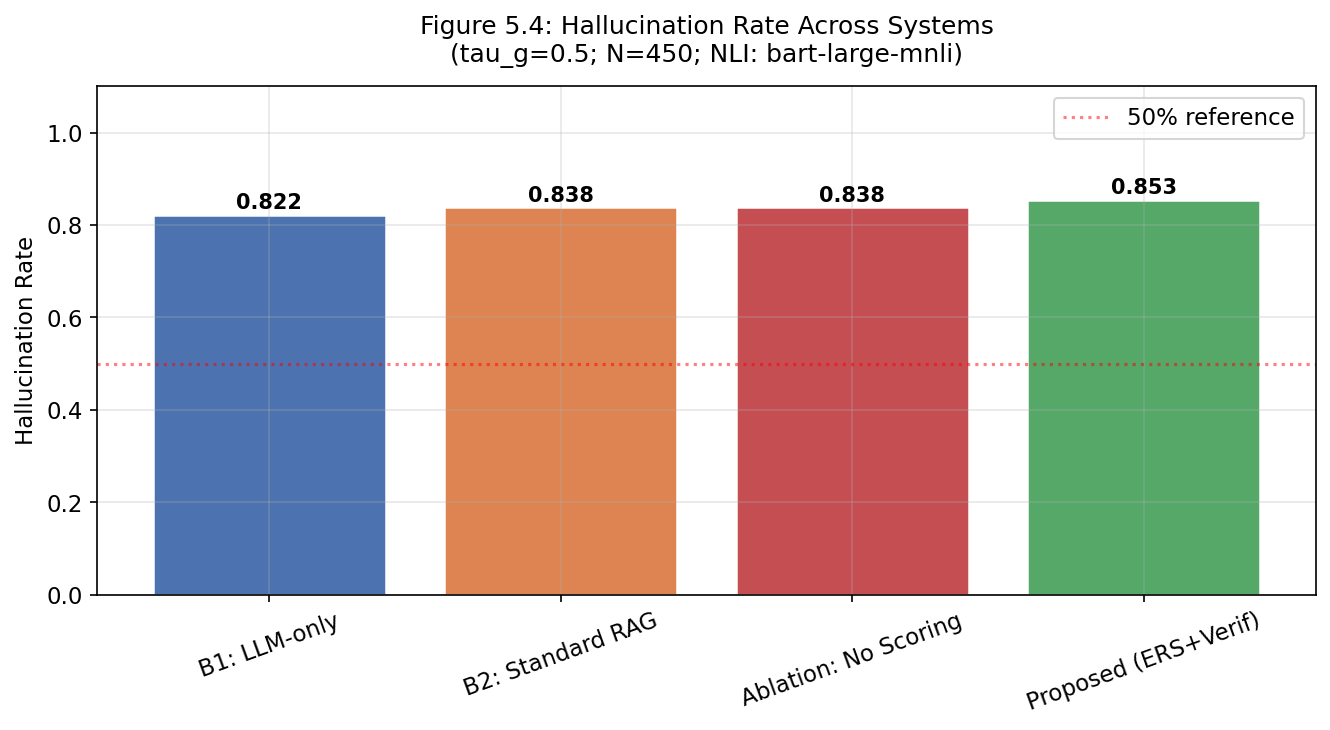

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_4_hallucination.png


In [9]:
# Cell 9: Figure 5.4 - Hallucination rates
sys_for_halluc  = ['b1', 'b2', 'abl_noscoring', 'proposed']
halluc_rates    = [ablation_results[s]['hallucination_rate'] for s in sys_for_halluc]
halluc_labels   = [SYS_LABELS[s] for s in sys_for_halluc]
halluc_colors   = [PALETTE[s] for s in sys_for_halluc]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(halluc_labels, halluc_rates, color=halluc_colors, edgecolor='white', linewidth=1.2)

for bar, val in zip(bars, halluc_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, 1.1)
ax.set_ylabel('Hallucination Rate')
ax.set_title(
    f'Figure 5.4: Hallucination Rate Across Systems\n'
    f'(tau_g=0.5; N={DS["total_claims"]}; NLI: bart-large-mnli)', pad=12
)
ax.tick_params(axis='x', rotation=20)
ax.axhline(y=0.5, color='red', linestyle=':', alpha=0.5, label='50% reference')
ax.legend()

plt.tight_layout()
fig54_path = os.path.join(FIG_DIR, 'fig5_4_hallucination.png')
plt.savefig(fig54_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig54_path}')

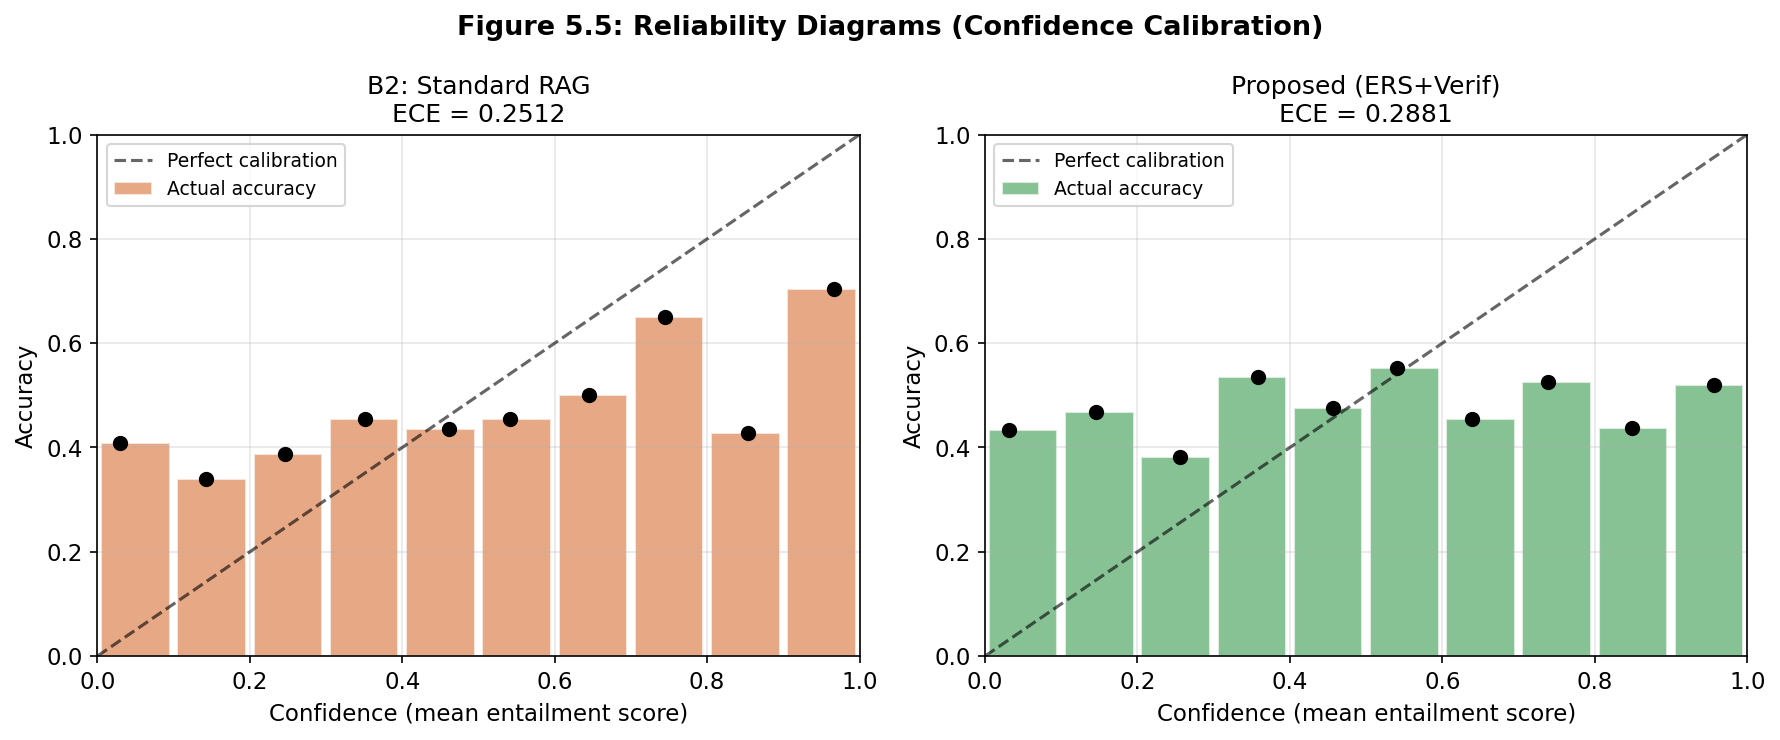

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_5_calibration.png


In [10]:
# Cell 10: Figure 5.5 - Reliability diagrams (calibration)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Figure 5.5: Reliability Diagrams (Confidence Calibration)',
             fontsize=13, fontweight='bold')

for ax, (system_name, bin_data, ece_val, color) in zip(
    axes,
    [
        ('B2: Standard RAG',      b2_bins, b2_ece, PALETTE['b2']),
        ('Proposed (ERS+Verif)',  pr_bins, pr_ece, PALETTE['proposed'])
    ]
):
    non_empty = [bd for bd in bin_data if bd['n'] > 0]
    bin_mids  = [(bd['bin_lo'] + bd['bin_hi']) / 2 for bd in non_empty]
    bin_accs  = [bd['acc']  for bd in non_empty]
    bin_confs = [bd['conf'] for bd in non_empty]

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Perfect calibration', alpha=0.6)
    ax.bar(bin_mids, bin_accs, width=0.09, alpha=0.7, color=color,
           edgecolor='white', label='Actual accuracy')
    ax.scatter(bin_confs, bin_accs, color='black', s=40, zorder=5)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Confidence (mean entailment score)')
    ax.set_ylabel('Accuracy')
    ax.set_title(f'{system_name}\nECE = {ece_val:.4f}')
    ax.legend(fontsize=9)

plt.tight_layout()
fig55_path = os.path.join(FIG_DIR, 'fig5_5_calibration.png')
plt.savefig(fig55_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig55_path}')

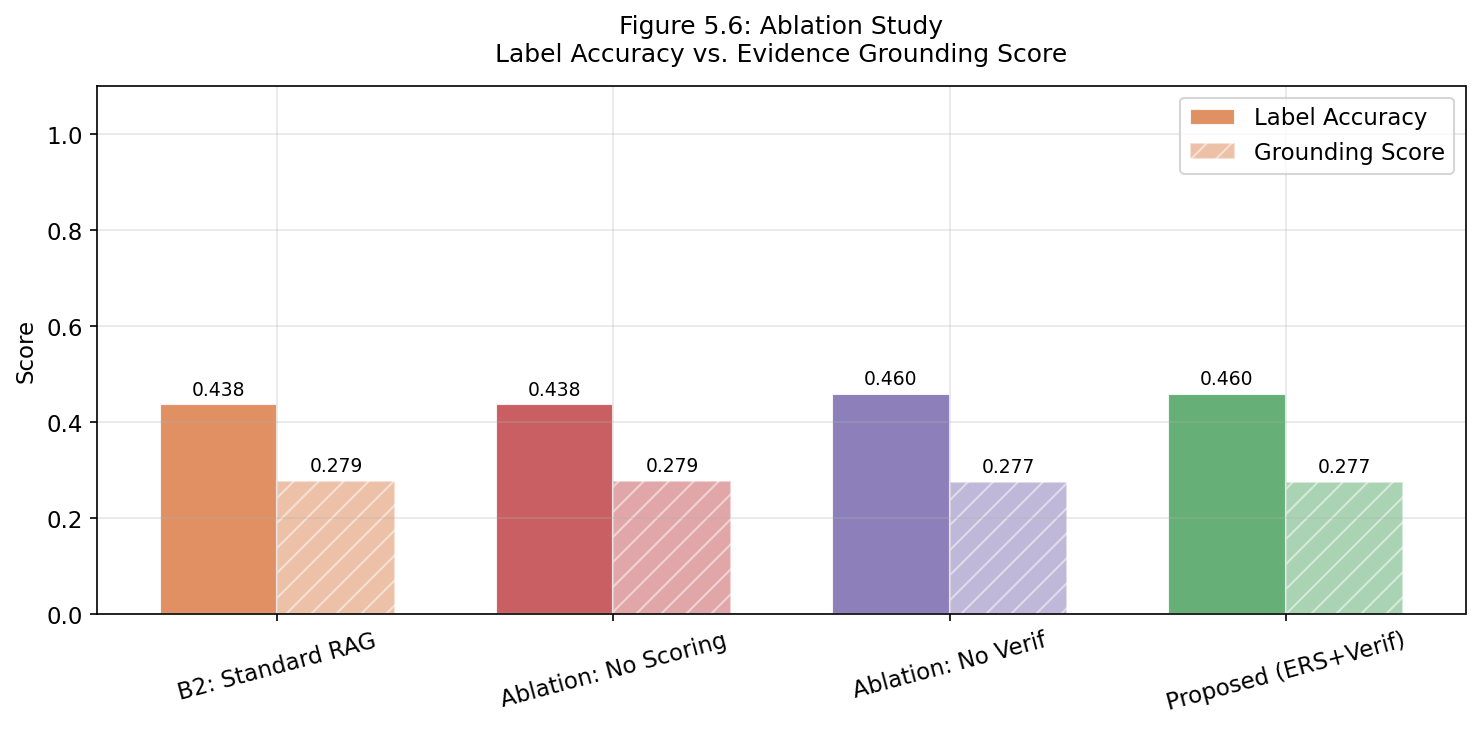

Saved: /content/drive/MyDrive/feverous-validation/figures/fig5_6_ablation.png


In [11]:
# Cell 11: Figure 5.6 - Ablation study
ablation_systems = ['b2', 'abl_noscoring', 'abl_noverif', 'proposed']
abl_labels = [SYS_LABELS[s] for s in ablation_systems]
abl_acc    = [ablation_results[s]['label_accuracy'] for s in ablation_systems]
abl_ground = [ablation_results[s]['grounding_score'] for s in ablation_systems]
abl_colors = [PALETTE[s] for s in ablation_systems]

x = np.arange(len(ablation_systems))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, abl_acc,    width, label='Label Accuracy',
               color=abl_colors, alpha=0.9, edgecolor='white')
bars2 = ax.bar(x + width/2, abl_ground, width, label='Grounding Score',
               color=abl_colors, alpha=0.5, edgecolor='white', hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(abl_labels, rotation=15)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Figure 5.6: Ablation Study\nLabel Accuracy vs. Evidence Grounding Score', pad=12)
ax.legend()

for bar, val in zip(bars1, abl_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9)
for bar, val in zip(bars2, abl_ground):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
fig56_path = os.path.join(FIG_DIR, 'fig5_6_ablation.png')
plt.savefig(fig56_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig56_path}')

In [12]:
# Cell 12: Save metrics_summary.json (single source of truth for all paper numbers)

metrics_summary = {
    'dataset': {
        'source':   'fever/feverous',
        'version':  'datasets==2.15.0',
        'license':  'CC BY-SA 3.0',
        'claims_total':     DS['total_claims'],
        'claims_per_label': 150,
        'corpus_size':      DS['corpus_size'],
        'gold_count':       DS['gold_count'],
        'distractor_count': DS['distractor_count'],
        'unresolved_ids':   DS.get('unresolved_evidence_ids', 'N/A'),
        'claims_without_evidence': DS.get('claims_without_resolved_evidence', 'N/A')
    },
    'retrieval': {
        'model':  'all-MiniLM-L6-v2',
        'index':  'FAISS IndexFlatIP (cosine, L2-normalized)',
        'metrics': {
            f'{m}@{k}': round(retr_df[f'{m}@{k}'].dropna().mean(), 5)
            for m in ['P', 'R'] for k in [5, 10, 20]
        }
    },
    'label_accuracy': {
        'b1_llm_only':     ablation_results['b1']['label_accuracy'],
        'b2_standard_rag': ablation_results['b2']['label_accuracy'],
        'proposed_ers':    ablation_results['proposed']['label_accuracy'],
        'abl_noscoring':   ablation_results['abl_noscoring']['label_accuracy'],
        'abl_noverif':     ablation_results['abl_noverif']['label_accuracy']
    },
    'hallucination': {
        'threshold_tau_g':  0.5,
        'nli_model':        'facebook/bart-large-mnli',
        'b1_halluc_rate':   ablation_results['b1']['hallucination_rate'],
        'b2_halluc_rate':   ablation_results['b2']['hallucination_rate'],
        'proposed_halluc':  ablation_results['proposed']['hallucination_rate']
    },
    'grounding_score': {
        'b1':       ablation_results['b1']['grounding_score'],
        'b2':       ablation_results['b2']['grounding_score'],
        'proposed': ablation_results['proposed']['grounding_score']
    },
    'calibration': {
        'confidence_definition': 'mean max-entailment score across justification sentences',
        'n_bins':       N_BINS,
        'b2_ece':       b2_ece,
        'proposed_ece': pr_ece
    },
    'ers_weights': {'w_relevance': 0.7, 'w_consistency': 0.3},
    'environment': {
        'platform':          'Google Colab free tier',
        'gpu':               'T4',
        'datasets_version':  '2.15.0',
        'huggingface_hub_version': '0.19.4',
        'fsspec_version':    '2023.10.0',
        'generation_model':  'mistralai/Mistral-7B-Instruct-v0.3 (4-bit, nf4)',
        'nli_model':         'facebook/bart-large-mnli',
        'embedding_model':   'all-MiniLM-L6-v2'
    }
}

summary_path = os.path.join(OUT_DIR, 'metrics_summary.json')
with open(summary_path, 'w') as f:
    json.dump(metrics_summary, f, indent=2)

print(f'Saved: {summary_path}')
print(json.dumps(metrics_summary, indent=2))

Saved: /content/drive/MyDrive/feverous-validation/outputs/metrics_summary.json
{
  "dataset": {
    "source": "fever/feverous",
    "version": "datasets==2.15.0",
    "license": "CC BY-SA 3.0",
    "claims_total": 450,
    "claims_per_label": 150,
    "corpus_size": 4571,
    "gold_count": 2071,
    "distractor_count": 2500,
    "unresolved_ids": 138,
    "claims_without_evidence": 2
  },
  "retrieval": {
    "model": "all-MiniLM-L6-v2",
    "index": "FAISS IndexFlatIP (cosine, L2-normalized)",
    "metrics": {
      "P@5": 0.35333,
      "P@10": 0.20667,
      "P@20": 0.11622,
      "R@5": 0.59355,
      "R@10": 0.64857,
      "R@20": 0.69418
    }
  },
  "label_accuracy": {
    "b1_llm_only": 0.3889,
    "b2_standard_rag": 0.4378,
    "proposed_ers": 0.46,
    "abl_noscoring": 0.4378,
    "abl_noverif": 0.46
  },
  "hallucination": {
    "threshold_tau_g": 0.5,
    "nli_model": "facebook/bart-large-mnli",
    "b1_halluc_rate": 0.8222,
    "b2_halluc_rate": 0.8378,
    "proposed_hallu

In [13]:
# Cell 13: Qualitative error analysis (3-5 failure cases from Proposed system)
pr_verif = verif_df[verif_df['system'] == 'proposed'].copy()
failures = pr_verif[pr_verif['correct'] == 0].head(5)

with open(os.path.join(DATA_DIR, 'claims.json'), encoding='utf-8') as f:
    all_claims = json.load(f)
claim_id_to_text = {c['claim_id']: c['claim'] for c in all_claims}

print('=== QUALITATIVE ERROR ANALYSIS (5 Proposed failures) ===')
print()

for i, (_, row) in enumerate(failures.iterrows()):
    claim_text = claim_id_to_text.get(row['claim_id'], '[not found]')
    print(f'--- Failure Case {i+1} ---')
    print(f'Claim:         {claim_text[:200]}')
    print(f'Gold label:    {row["gold_label"]}')
    print(f'Predicted:     {row["pred_label"]}')
    print(f'Grounding:     {row["mean_entailment"]:.4f}')
    print(f'Hallucination: {"YES" if row["has_hallucination"] else "NO"}')
    print(f'Justification: {str(row["justification"])[:300]}')
    print()

error_path = os.path.join(OUT_DIR, 'error_analysis.csv')
failures.to_csv(error_path, index=False)
print(f'Saved: {error_path}')

=== QUALITATIVE ERROR ANALYSIS (5 Proposed failures) ===

--- Failure Case 1 ---
Claim:         William Dering is first recorded as a dancing master in Philadelphia, he is said to have been respected as well for his talents on the French horn and in 1737 he moved to Gloucester County which was f
Gold label:    NOT ENOUGH INFO
Predicted:     SUPPORTS
Grounding:     0.9512
Hallucination: NO
Justification: The claim that William Dering was a dancing master in Philadelphia from 1735 to 1736 and moved to Gloucester County, Virginia in 1737 is supported by the evidence that he was indeed recorded as a dancing master in Philadelphia during that time period and he was in Gloucester County, Virginia by 1737

--- Failure Case 2 ---
Claim:         Final classification for the 2011 Bayern-Rundfahrt was General Classification: Geraint Thomas, Points Classification: Edvald Boasson Hagen, Mountains Classification: Pieter Serry, Young Rider Classifi
Gold label:    NOT ENOUGH INFO
Predicted:     SUPPOR

## Day 6 Complete

Files saved:
- `figures/fig5_1_label_accuracy.png`
- `figures/fig5_2_retrieval.png`
- `figures/fig5_4_hallucination.png`
- `figures/fig5_5_calibration.png`
- `figures/fig5_6_ablation.png`
- `outputs/metrics_summary.json` (single source of truth for all paper numbers)
- `outputs/error_analysis.csv`

Next: Open `Day7_Paper_Update.ipynb`